# 02 — Investigating Activity Regimes, Label Observability & Predictability
**Big Data Analytics Techniques and Applications · Assignment 2 (2026)**  

> **Purpose.** Notebook `01_data_audit.ipynb` established that the eight-table dataset is structurally consistent, but raised questions about the mid-year activity drop, user sparsity, timestamp/label ambiguity, and representativeness of historical test periods. This notebook **tests those hypotheses more carefully**, rather than building a model. It does **not import, execute, or depend on notebook 01**.
>
> **Snapshot caveat.** The numbers in the next section are a *frozen summary from notebook 01 executed on 2026-10-14 before the 21:00 Taiwan daily release*. They are not automatically updated. Every later table/plot in this notebook **recomputes from the current files on disk**.

## Executive handoff — findings from `01_data_audit.ipynb`

| Topic | What notebook 01 actually measured | What remains unresolved / implication |
|---|---|---|
| **Snapshot** | Local course clone SHA `506d860693df...`; newest `Pushes.created_at`: **2026-10-13 20:59:29 Taiwan** | This is **not** the Oct 14 21:00 refresh. Re-run after a fresh instructor clone. |
| **Size / integrity** | **2,552,788** total rows; 8 Parquet tables; **9,000 cohort users**, 45,590 total `Users`; **0** duplicate/null PKs and **0** orphan non-null FKs across 20 declared edges | Joins are structurally feasible; entities beyond the cohort have **incomplete** activity records. |
| **Dominance** | `Pushes` **1,661,256 rows**; next-largest source `PullRequests` **301,518** | Six activities have very different frequencies. Rows in PR/Issues/Reviews are **entity/observation** records, not necessarily opening/submission events. |
| **Time regime** | Weekly participation chart showed a large **June–August decline** and **September rebound** relative to earlier months | Is it a genuine cohort shift, different users being active, event count changes, or a collection artifact? Causal explanation **not established**. |
| **Sparsity** | At **2026-10-01 00:00 Taiwan** over 9,000 cohort users, past-7-day participation: push **29.19%**; open-PR proxy **5.31%**; issue proxy **3.30%**; issue comments **3.87%**; review proxy **3.81%**; review comments **2.59%** | Final test users are selected for activity; all-cohort prevalence is **not** the official test prevalence. Need examine selection effects and repeat behavior. |
| **Temporal ambiguity** | `PullRequests.created_at` **55.20% missing** (and `author_id` similarly missing). Of nonmissing paired timestamps, `first_seen_at > event_time + 7d` for **2.27% PR**, **20.99% Issue**, **0.13% PRReview** rows | **Never equate** `first_seen_at` with an actual `open_pr`, `open_issue`, or `pr_review` event without qualification. Need per-week proxy disagreement and visibility-lag analysis. |
| **Relational breadth** | Prior 30 days: 1,903 cohort users pushed in ≥2 distinct repositories; 414 had observed PR reviews in ≥2 repositories | Relationship diversity may predict later behavior, **not demonstrated yet**. Compare outcomes by relationship breadth. |
| **Leakage** | At Oct 1 cutoff, using final-snapshot late-known timestamp fields without masking would expose **8 merged_at**, **8 PR closed_at**, **25 Issue closed_at** future values in already-visible records | Features must be point-in-time safe; exclude or guard late-known fields. |

**Interpretation guardrails:** The six required prediction labels are `open_pr`, `open_issue`, `issue_comment`, `pr_review`, `pr_review_comment`, `push`. For exploratory plots the first, second, and fourth signals are **first-observation proxies** rather than verified events. All Parquet timestamps are naive **UTC**; assignment deadlines and weekly forecasts use **Asia/Taipei**. Model scoring is `(macro-F1 + micro-F1)/2`. This follow-up does not claim ground-truth future labels are recoverable from the snapshot.

## 1. What this follow-up tests

1. **Regime shift:** quantify monthly/weekly activity changes using both active-user counts and records per active user, excluding incomplete weeks. Compare *the same cohort IDs* across periods to distinguish churn from within-user changes.
2. **Observation versus event time:** quantify delayed discovery, missing identities, and disagreements between `first_seen_at` and event timestamp windows for PRs/issues/reviews.
3. **Participation and selection:** compare activity across full cohort versus an **approximate** ≥5-record/90-day eligibility proxy. This **does not reconstruct** the TA's official test roster.
4. **Short-term predictability:** measure the next-week occurrence rate conditioned on previous-week activity **using only direct-event signals** (`push`, `issue_comment`, `pr_review_comment`). These are descriptive associations, **not trained-model scores**.
5. **Relational context:** compare future push participation across groups with different numbers of previously visited repositories.
6. **Daily release drift:** distinguish a new Git SHA/release from simply rerunning notebook; compare to notebook 01's optional lightweight snapshot log.

**Policies:** Read **only** the official local `data/legacy/assignment2/data/db/*.parquet` and `assignment2/evaluation/test_input.csv` if present. Do not query APIs or collect additional GitHub records. No automatic `git pull` or clone in the notebook. Rerun after you **manually replace the instructor clone** when a new release is published around **21:00 Taiwan** (the final release is Nov 11, 21:00).

## 2. Setup and reproducibility

Expected placement:

```text
Assignment 2/                    # personal repository
├── notebooks/
│   ├── 01_data_audit.ipynb
│   └── 02_deeper_data_analysis.ipynb   # THIS FILE
├── assignment2/               # independent, ignored official clone
│   ├── data/db/*.parquet
│   └── evaluation/test_input.csv (once released)
├── experiments/eda_snapshot_history.jsonl (optional, from 01)
└── environment.yaml
```

1. Activate your environment defined in `environment.yaml` and use its Jupyter kernel.
2. After each 21:00 release, **re-clone the official `assignment2` folder** (the instructor force-replaces Git history; don't `git pull`). Keep your code *outside* that folder.
3. Restart this notebook kernel and **Run All**. The paths and release details are automatically detected. The notebook is **read-only**.
4. To relocate the dataset, set `ASG2_DATA_DIR` to the absolute path of `data/legacy/assignment2/data/db` before starting the kernel, or edit the override below.

Analysis windows are configurable below; snapshots may include older records newly discovered later, so repeated analysis of earlier periods can change after re-cloning.

In [1]:
from __future__ import annotations

import json
import os
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import pyarrow.parquet as pq

# ---------------- CONFIGURATION ----------------
DATA_DIR_OVERRIDE = os.environ.get("ASG2_DATA_DIR", "")
TZ = "Asia/Taipei"
LOOKBACK_DAYS = 90  # historical activity-selection proxy
MIN_ELIGIBILITY_RECORDS = 5  # proxy only; official TA selection cannot be reconstructed exactly
RECENT_COMPLETE_WEEKS = 12  # week-to-week persistence / eligibility study
RELATIONAL_LOOKBACK_DAYS = 30

TABLES = ("Users", "Repositories", "PullRequests", "Issues", "IssueComments",
          "PRReviews", "PRReviewComments", "Pushes")
ROW_TIMES = {t: ("created_at" if t in ("IssueComments", "PRReviewComments", "Pushes")
                 else "first_seen_at") for t in TABLES}
ACTIVITY_SPEC = {
    # (source table, actor FK, row-visibility timestamp, optional filter column)
    "open_pr": ("PullRequests", "author_id", "first_seen_at", None),
    "open_issue": ("Issues", "author_id", "first_seen_at", "is_pull_request"),
    "issue_comment": ("IssueComments", "author_id", "created_at", None),
    "pr_review": ("PRReviews", "reviewer_id", "first_seen_at", None),
    "pr_review_comment": ("PRReviewComments", "author_id", "created_at", None),
    "push": ("Pushes", "user_id", "created_at", None),
}
DIRECT_SIGNALS = ("push", "issue_comment", "pr_review_comment")
PROXY_SIGNALS = ("open_pr", "open_issue", "pr_review")


def locate_data(override=""):
    if override:
        base = Path(override).expanduser().resolve()
        candidates = [base, base / "db", base / "data/db", base / "data/legacy/assignment2/data/db"]
    else:
        candidates = [base / "data/legacy/assignment2/data/db"
                      for base in (Path.cwd(), *Path.cwd().parents)]
    for candidate in candidates:
        if all((candidate / (t + ".parquet")).is_file() for t in TABLES):
            return candidate
    raise FileNotFoundError("Expected 8 Parquet files under <project>/data/legacy/assignment2/data/db. "
                            "Clone the official course repository or set ASG2_DATA_DIR.")

DATA_DIR = locate_data(DATA_DIR_OVERRIDE)
OFFICIAL_REPO = DATA_DIR.parent.parent
PROJECT_ROOT = next((p for p in OFFICIAL_REPO.parents if (p / "src").is_dir()), OFFICIAL_REPO.parent)
HISTORY_LOG = PROJECT_ROOT / "experiments/eda_snapshot_history.jsonl"


def read_columns(table, columns):
    columns = list(dict.fromkeys(columns))
    available = set(pq.ParquetFile(DATA_DIR / (table + ".parquet")).schema_arrow.names)
    missing = set(columns) - available
    if missing:
        raise ValueError(f"{table} missing expected columns: {sorted(missing)}")
    return pd.read_parquet(DATA_DIR / (table + ".parquet"), columns=columns)


def as_utc(series):
    """Treat source's timezone-naive datetime64[ns] values as UTC."""
    return pd.to_datetime(series, errors="coerce", utc=True)


def local_week(series):
    """Return Monday start, naive Taiwan wall time (plotting/grouping only)."""
    loc = as_utc(series).dt.tz_convert(TZ).dt.tz_localize(None)
    return loc.dt.to_period("W-SUN").dt.start_time


def cutoff_utc(local_value):
    stamp = pd.Timestamp(local_value)
    if stamp.tzinfo is None:
        stamp = stamp.tz_localize(TZ)
    return stamp.tz_convert("UTC")


def repo_commit(path):
    if not (path / ".git").exists():
        return None
    try:
        return subprocess.run(["git", "-C", str(path), "rev-parse", "HEAD"],
                              capture_output=True, text=True, check=True, timeout=8).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return None

print("Project:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Notebook engine:", f"pandas {pd.__version__}, NumPy {np.__version__}")
print("External collection: disabled; all data is from local instructor files")

Project: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2
Data directory: c:\Users\Davon\Desktop\Master\Semester 3\535703 Big Data Analytics\Assignment 2\assignment2\data\db
Notebook engine: pandas 2.3.3, NumPy 2.4.6
External collection: disabled; all data is from local instructor files


## 3. Current snapshot provenance and usable coverage

The next tables are **live**. Every time this notebook is rerun, they reflect the current local Parquet files. The official repository's commit is the best snapshot identifier; filesystem timestamps can change when a clone is downloaded even if the upstream content did not.

To avoid falsely treating the current partial week as a genuine dip, later weekly comparisons use **complete Monday-to-Monday weeks**, based on the latest observed event in the data, not today's wall clock. This is an operational completeness proxy, not proof all events were collected.

In [2]:
sha = repo_commit(OFFICIAL_REPO)
release_rows = []
for table in TABLES:
    f = DATA_DIR / f"{table}.parquet"
    meta = pq.ParquetFile(f)
    t = as_utc(read_columns(table, [ROW_TIMES[table]])[ROW_TIMES[table]])
    release_rows.append({"table": table, "rows": meta.metadata.num_rows,
                         "file_MB": round(f.stat().st_size / (1024**2), 2),
                         "min_UTC": t.min(), "max_UTC": t.max()})
release_df = pd.DataFrame(release_rows)
observed_max = release_df["max_UTC"].max()
observed_max_tw = observed_max.tz_convert(TZ)
# A complete week finishes Monday at 00:00 Taiwan; the last observation is not a guarantee of full capture.
last_completed_monday = observed_max_tw.tz_localize(None).to_period("W-SUN").start_time
# Time windows [W, W+7d) with W+7d <= last_completed_monday.
first_week = (release_df["min_UTC"].min().tz_convert(TZ)
              .tz_localize(None).to_period("W-SUN").start_time)
complete_weeks = pd.date_range(first_week, last_completed_monday - pd.Timedelta(days=7), freq="W-MON")
print("Official clone Git SHA:", sha or "Not available (copied data?)")
print("Newest observed row time:", observed_max_tw)
print("Complete weeks in this analysis:", len(complete_weeks),
      "through", complete_weeks[-1].date() if len(complete_weeks) else "none")
print("Total table rows:", int(release_df.rows.sum()))
display(release_df)
assert len(complete_weeks) >= 4, "Need >=4 complete weeks for meaningful temporal analysis"

Official clone Git SHA: 506d860693df60a698b68aa63a8edb4a984c8e1b
Newest observed row time: 2026-10-13 20:59:29+08:00
Complete weeks in this analysis: 45 through 2026-10-05
Total table rows: 2552788


,table,rows,file_MB,min_UTC,max_UTC
0,Users,45590,1.20,2025-12-01 00:01:12+00:00,2026-10-13 12:51:56+00:00
1,Repositories,109081,4.13,2025-12-01 00:01:12+00:00,2026-10-13 12:56:36+00:00
2,PullRequests,301518,25.51,2025-12-01 00:03:36+00:00,2026-10-13 12:47:07+00:00
3,Issues,172007,63.33,2025-12-01 00:01:55+00:00,2026-10-13 12:51:56+00:00
4,IssueComments,106204,18.01,2025-12-01 00:01:55+00:00,2026-10-13 12:38:07+00:00
5,PRReviews,90710,7.03,2025-12-01 00:26:48+00:00,2026-10-13 12:41:43+00:00
6,PRReviewComments,66422,20.09,2025-12-01 00:30:42+00:00,2026-10-13 11:32:36+00:00
7,Pushes,1661256,40.86,2025-12-01 00:01:12+00:00,2026-10-13 12:59:29+00:00


## 4. Build a minimal in-memory *observation* index (not training labels)

For the six activities, create consistent cohort-indexed event-time series from the official tables. `open_pr`, `open_issue`, and `pr_review` are **first-observation proxies**; they will be displayed with `*` when interpreted as activity. The remaining three are direct activity-event rows.

`user_id` fields used below are **internal** FK indices valid only within this *single snapshot*. External test identities use `Users.github_user_id`; never save these internal indices for cross-release joins.

In [3]:
users = read_columns("Users", ["user_id", "github_user_id", "is_cohort", "is_bot", "first_seen_at"])
assert users["user_id"].is_unique and users["github_user_id"].is_unique
cohort = users.loc[users["is_cohort"].eq(True)].copy()
cohort_ids = pd.Index(cohort["user_id"])
COHORT_SIZE = len(cohort_ids)
print("Cohort users:", COHORT_SIZE, "| Other reference users:", len(users) - COHORT_SIZE)
print("Bots in cohort:", int(cohort["is_bot"].fillna(False).sum()))
observations = {}
for activity, (table, actor_col, time_col, issue_flag) in ACTIVITY_SPEC.items():
    requested = [actor_col, time_col, "repo_id"] + ([issue_flag] if issue_flag else [])
    d = read_columns(table, requested)
    if issue_flag:
        d = d.loc[d[issue_flag].eq(False)]
    d = d.loc[d[actor_col].isin(cohort_ids), [actor_col, time_col, "repo_id"]].copy()
    d.rename(columns={actor_col: "internal_user_id"}, inplace=True)
    d["timestamp_utc"] = as_utc(d[time_col])
    d = d[["internal_user_id", "repo_id", "timestamp_utc"]].dropna(subset=["timestamp_utc"])
    d["week_tw"] = local_week(d["timestamp_utc"])
    observations[activity] = d
print("Observation index loaded; no labels or trained model created")
display(pd.DataFrame([{"signal": a + ("*" if a in PROXY_SIGNALS else ""),
                       "rows_attributed_to_cohort": len(d),
                       "unique_cohort_users": d["internal_user_id"].nunique()}
                      for a, d in observations.items()]))

Cohort users: 9000 | Other reference users: 36590
Bots in cohort: 0
Observation index loaded; no labels or trained model created


,signal,rows_attributed_to_cohort,unique_cohort_users
0,open_pr*,130043,7456
1,open_issue*,83543,4059
2,issue_comment,106204,4712
3,pr_review*,89538,3483
4,pr_review_comment,66422,2726
5,push,1661256,8932


## 5. Investigate the mid-year decline and September recovery

**Question:** Did the number of active users change, the volume per active user change, or both? Weekly row totals alone cannot distinguish these. Use **completed Taiwan calendar weeks**, including zero-activity weeks, and compare the *same* cohort population.

**Pre-declared descriptive periods (not a causal claim):**

- **Early:** 2025-12 through 2026-05
- **Dip:** 2026-06 through 2026-08
- **Recovery:** 2026-09 onward

An observational shift may reflect user behavior, sampling/collection effects, or something else. This notebook cannot determine the cause.

Rows are grouped by visibility times for open_pr/open_issue/pr_review (proxies).


,signal,regime,weeks,median_weekly_users,median_weekly_rows,median_rows_per_active
0,issue_comment,Dip (Jun–Aug),14,161.0,300.5,1.64
1,issue_comment,Early (Dec–May),26,996.0,3378.5,3.76
2,issue_comment,Recovery (Sep+),5,470.0,1392.0,2.96
3,open_issue,Dip (Jun–Aug),14,129.0,338.5,2.65
4,open_issue,Early (Dec–May),26,605.0,2493.0,4.11
5,open_issue,Recovery (Sep+),5,386.0,1815.0,4.7
6,open_pr,Dip (Jun–Aug),14,193.5,295.5,1.46
7,open_pr,Early (Dec–May),26,1287.5,4258.5,3.22
8,open_pr,Recovery (Sep+),5,635.0,1341.0,2.11
9,pr_review,Dip (Jun–Aug),14,142.5,219.0,1.39


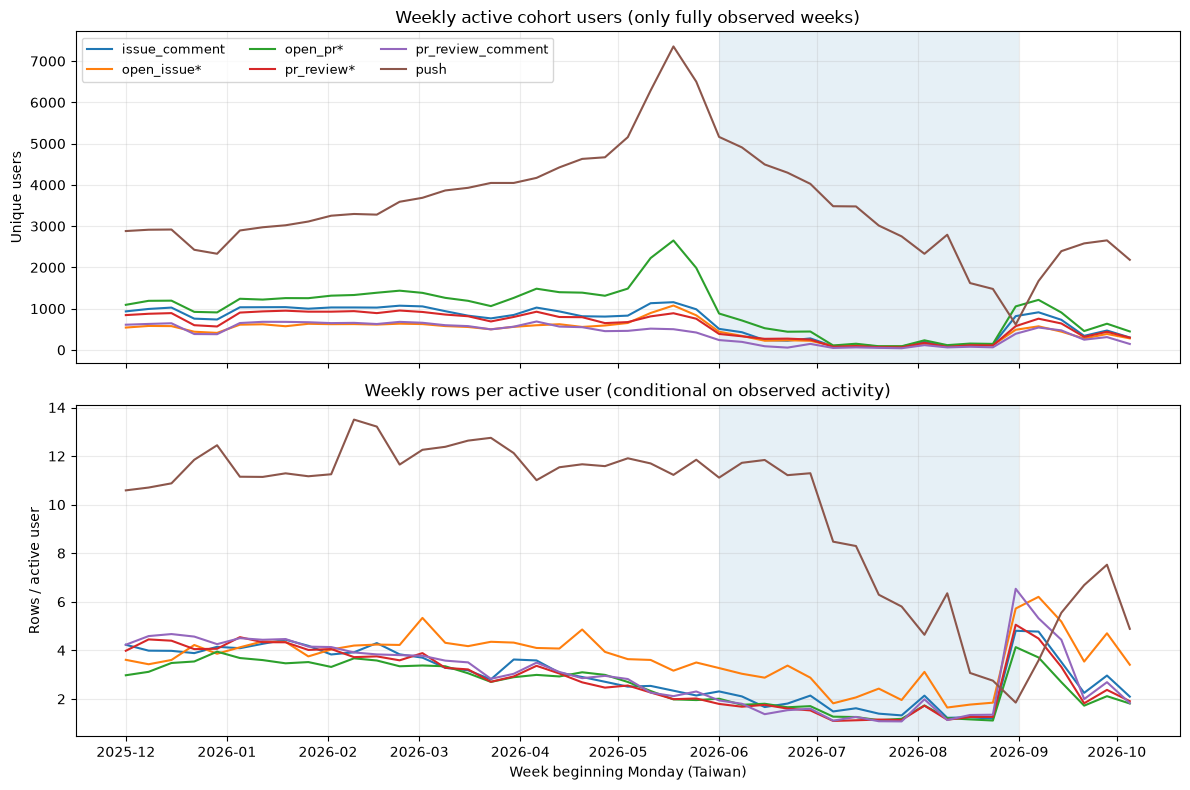

push: dip/early median weekly active users = 0.89x
issue_comment: dip/early median weekly active users = 0.16x
pr_review_comment: dip/early median weekly active users = 0.12x


In [4]:
idx = pd.MultiIndex.from_product([list(ACTIVITY_SPEC), complete_weeks], names=["signal", "week_tw"])
weekly_parts = []
for activity, d in observations.items():
    g = d.groupby("week_tw").agg(rows=("internal_user_id", "size"),
                                  users=("internal_user_id", "nunique"))
    g = g.reindex(complete_weeks, fill_value=0)
    g["signal"] = activity
    g["week_tw"] = g.index
    weekly_parts.append(g.reset_index(drop=True))
weekly = pd.concat(weekly_parts, ignore_index=True)
weekly["active_pct"] = 100 * weekly["users"] / max(COHORT_SIZE, 1)
weekly["rows_per_active_user"] = weekly["rows"] / weekly["users"].replace(0, np.nan)

monthly = weekly.copy()
monthly["month"] = monthly["week_tw"].dt.to_period("M").astype(str)

def regime(week):
    if week < pd.Timestamp("2026-06-01"):
        return "Early (Dec–May)"
    elif week < pd.Timestamp("2026-09-01"):
        return "Dip (Jun–Aug)"
    return "Recovery (Sep+)"

weekly["regime"] = weekly["week_tw"].map(regime)
regime_summary = (weekly.groupby(["signal", "regime"], as_index=False)
                   .agg(weeks=("week_tw", "nunique"),
                        median_weekly_users=("users", "median"),
                        median_weekly_rows=("rows", "median"),
                        median_rows_per_active=("rows_per_active_user", "median")))
print("Rows are grouped by visibility times for open_pr/open_issue/pr_review (proxies).")
display(regime_summary.round(2))

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for signal, group in weekly.groupby("signal"):
    name = signal + ("*" if signal in PROXY_SIGNALS else "")
    axes[0].plot(group.week_tw, group.users, label=name)
    axes[1].plot(group.week_tw, group.rows_per_active_user, label=name)
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-06-01"), pd.Timestamp("2026-09-01"), alpha=.11)
    ax.grid(alpha=.25)
axes[0].set_title("Weekly active cohort users (only fully observed weeks)")
axes[0].set_ylabel("Unique users")
axes[1].set_title("Weekly rows per active user (conditional on observed activity)")
axes[1].set_ylabel("Rows / active user")
axes[1].set_xlabel("Week beginning Monday (Taiwan)")
axes[0].legend(ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

# Regime-level calculated comparisons; change with newer releases.
for signal in DIRECT_SIGNALS:
    rows = regime_summary.loc[regime_summary.signal.eq(signal)].set_index("regime")
    if {"Early (Dec–May)", "Dip (Jun–Aug)"}.issubset(rows.index):
        e, d = rows.loc["Early (Dec–May)", "median_weekly_users"], rows.loc["Dip (Jun–Aug)", "median_weekly_users"]
        print(f"{signal}: dip/early median weekly active users = {d/e:.2f}x" if e else f"{signal}: early reference is zero")

### 5.1 Are the same users responsible for the drop and rebound?

Compare the *sets* of cohort GitHub users active within each period. High overlap suggests changes in frequency among existing participants; low overlap suggests turnover in which users participate. Neither result proves why the change occurred.

We examine `push` and the two direct comment signals to avoid conflating observed entities with emitted events.

In [5]:
def period_name(time_tw):
    return regime(pd.Timestamp(time_tw))

turnover = []
for activity in DIRECT_SIGNALS:
    d = observations[activity]
    d = d.loc[d.week_tw.isin(complete_weeks)]
    groups = {name: set(grp.internal_user_id.dropna().astype("int64"))
              for name, grp in d.groupby(d.week_tw.map(period_name))}
    first = groups.get("Early (Dec–May)", set())
    dip = groups.get("Dip (Jun–Aug)", set())
    recover = groups.get("Recovery (Sep+)", set())
    for x, y, a, b in [("Early", "Dip", first, dip), ("Dip", "Recovery", dip, recover)]:
        denom = len(a | b)
        turnover.append({"signal": activity, "pair": f"{x} → {y}", "earlier_active": len(a),
                         "later_active": len(b), "both": len(a & b),
                         "jaccard": round(len(a & b)/denom, 3) if denom else np.nan,
                         "new_in_later": len(b - a), "missing_from_later": len(a-b)})
display(pd.DataFrame(turnover))
print("Caution: periods have different lengths. Overlap compares membership, not per-week activity probability.")

,signal,pair,earlier_active,later_active,both,jaccard,new_in_later,missing_from_later
0,push,Early → Dip,8914,7438,7421,0.831,17,1493
1,push,Dip → Recovery,7438,4364,4217,0.556,147,3221
2,issue_comment,Early → Dip,4412,1768,1560,0.338,208,2852
3,issue_comment,Dip → Recovery,1768,1509,973,0.422,536,795
4,pr_review_comment,Early → Dip,2520,908,781,0.295,127,1739
5,pr_review_comment,Dip → Recovery,908,927,536,0.413,391,372


Caution: periods have different lengths. Overlap compares membership, not per-week activity probability.


## 6. Delayed discovery: event time versus row visibility

For `PullRequests`, `Issues`, `PRReviews`, compare candidate original event timestamps (`created_at`/`submitted_at`) with when the row first became observable (`first_seen_at`). Keep **all rows** for the global delay analysis, then separately inspect **cohort-attributed** rows for task relevance. Report missing-event and missing-actor rates rather than silently dropping them.

Even when the original timestamp is present, the provided tables may not retain a distinct original event/action proving the user emitted a particular target action in that period. These are diagnostics, not official labels.

,table,scope,rows,actor_null_pct,event_time_missing_pct,median_delay_days,p90_delay_days,p99_delay_days,delay_gt_1d_pct_of_paired,delay_gt_7d_pct_of_paired
0,PullRequests,all_rows,301518,55.2,55.2,0.00,0.00,25.32,4.66,2.27
1,PullRequests,cohort_actor,130043,0.0,0.0,0.00,0.00,8.81,2.64,1.16
2,Issues,all_rows,125508,0.0,0.0,0.03,80.15,1870.86,33.27,21.63
3,Issues,cohort_actor,83543,0.0,0.0,0.00,8.58,618.12,18.48,10.82
4,PRReviews,all_rows,90710,0.0,0.0,0.00,0.00,0.09,0.45,0.13
5,PRReviews,cohort_actor,89538,0.0,0.0,0.00,0.00,0.00,0.13,0.03


table,Issues,PRReviews,PullRequests
lag_bin,,,
0–1h,65.14,84.98,3.23
1h–1d,10.71,0.32,2.14
1–7d,7.66,0.10,1.47
7–30d,4.69,0.02,0.76
>30d,6.12,0.01,0.41
≤0d,5.67,14.57,92.00


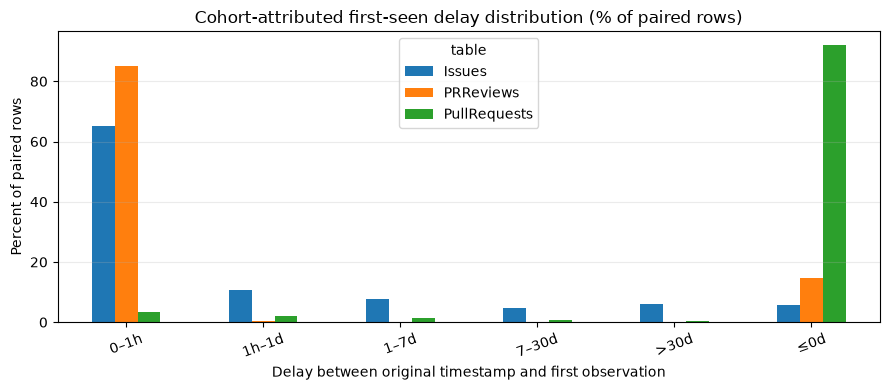

In [6]:
VISIBILITY_TABLES = {
    "PullRequests": ("created_at", "author_id", None),
    "Issues": ("created_at", "author_id", "is_pull_request"),
    "PRReviews": ("submitted_at", "reviewer_id", None),
}
visibility_details = {}
lag_summary = []
for table, (event_field, actor, exclude_pr) in VISIBILITY_TABLES.items():
    cols = [event_field, "first_seen_at", actor] + ([exclude_pr] if exclude_pr else [])
    data = read_columns(table, cols)
    if exclude_pr:
        data = data.loc[data[exclude_pr].eq(False)]
    data = data.copy()
    data["event_utc"] = as_utc(data[event_field]); data["seen_utc"] = as_utc(data.first_seen_at)
    data["delay_days"] = (data.seen_utc - data.event_utc).dt.total_seconds().div(86400)
    data["cohort_actor"] = data[actor].isin(cohort_ids)
    visibility_details[table] = data
    for scope, frame in [("all_rows", data), ("cohort_actor", data.loc[data.cohort_actor])]:
        valid = frame.delay_days.dropna()
        lag_summary.append({"table": table, "scope": scope, "rows": len(frame),
                            "actor_null_pct": round(100*frame[actor].isna().mean(), 2) if len(frame) else np.nan,
                            "event_time_missing_pct": round(100*frame.event_utc.isna().mean(), 2) if len(frame) else np.nan,
                            "median_delay_days": round(valid.median(), 2) if len(valid) else np.nan,
                            "p90_delay_days": round(valid.quantile(.90), 2) if len(valid) else np.nan,
                            "p99_delay_days": round(valid.quantile(.99), 2) if len(valid) else np.nan,
                            "delay_gt_1d_pct_of_paired": round(100*(valid>1).mean(), 2) if len(valid) else np.nan,
                            "delay_gt_7d_pct_of_paired": round(100*(valid>7).mean(), 2) if len(valid) else np.nan})
lag_df = pd.DataFrame(lag_summary)
display(lag_df)

bins = [-np.inf, 0, 1/24, 1, 7, 30, np.inf]
labels = ["≤0d", "0–1h", "1h–1d", "1–7d", "7–30d", ">30d"]
hist = []
for table, d in visibility_details.items():
    x = d.loc[d.cohort_actor, "delay_days"].dropna()
    cat = pd.cut(x, bins=bins, labels=labels)
    props = cat.value_counts().reindex(labels, fill_value=0)
    for group, value in props.items():
        hist.append({"table": table, "lag_bin": group,
                     "paired_cohort_rows": len(x), "rows": int(value),
                     "pct": round(100*value/max(1,len(x)), 2)})
lag_bins_df = pd.DataFrame(hist)
display(lag_bins_df.pivot(index="lag_bin", columns="table", values="pct"))
ax = lag_bins_df.pivot(index="lag_bin", columns="table", values="pct").plot(kind="bar", figsize=(9, 4))
ax.set_title("Cohort-attributed first-seen delay distribution (% of paired rows)")
ax.set_ylabel("Percent of paired rows")
ax.set_xlabel("Delay between original timestamp and first observation")
ax.grid(axis="y", alpha=.25)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 6.1 Does the weekly *proxy* agree with the available original event timestamp?

For each of the **last 8 complete weeks** and each cohort actor with a known timestamp, compare:

- **First-seen proxy:** at least one row first visible during week W.
- **Candidate event-time signal:** at least one matching row whose `created_at`/`submitted_at` is within week W.

Compute **set overlap, proxy-only, event-time-only and Jaccard**. Differences reveal why naïvely using `first_seen_at` as a label timestamp is dangerous, but **neither view constitutes independently verified official target ground truth**. In particular, rows discovered after the period may still retroactively appear in today's snapshot.

In [7]:
window_comparisons = []
selected_weeks = list(complete_weeks[-8:])
for table, data in visibility_details.items():
    cohort_rows = data.loc[data.cohort_actor]
    field = VISIBILITY_TABLES[table][1]
    for week in selected_weeks:
        start = cutoff_utc(week); end = start + pd.Timedelta(days=7)
        seen_mask = (cohort_rows.seen_utc >= start) & (cohort_rows.seen_utc < end)
        event_mask = (cohort_rows.event_utc >= start) & (cohort_rows.event_utc < end)
        seen = set(cohort_rows.loc[seen_mask, field].dropna().astype("int64"))
        event = set(cohort_rows.loc[event_mask, field].dropna().astype("int64"))
        window_comparisons.append({"source": table, "week_Taiwan": week.date(),
                                   "proxy_users": len(seen), "candidate_users": len(event),
                                   "intersection": len(seen & event),
                                   "proxy_only": len(seen-event), "event_only": len(event-seen),
                                   "jaccard": round(len(seen&event)/len(seen|event), 3) if (seen|event) else np.nan})
compare_df = pd.DataFrame(window_comparisons)
display(compare_df)
print("Aggregated weekly disagreement (counts pooled across weeks; user-week pairs can repeat):")
display(compare_df.groupby("source", as_index=False)[["proxy_users","candidate_users","intersection","proxy_only","event_only"]].sum())

# How many records whose candidate date was in a historical window were not yet visible by its end?
late_reveal = []
for table, d in visibility_details.items():
    cohort_rows = d.loc[d.cohort_actor]
    for week in selected_weeks:
        start=cutoff_utc(week); end=start+pd.Timedelta(days=7)
        original_in_week=(cohort_rows.event_utc>=start)&(cohort_rows.event_utc<end)
        subset=cohort_rows.loc[original_in_week]
        late_reveal.append({"table":table, "week_Taiwan":str(week.date()),
                            "cohort_rows_with_candidate_time_in_week":len(subset),
                            "not_first_seen_until_after_week":int((subset.seen_utc>=end).sum())})
display(pd.DataFrame(late_reveal))

,source,week_Taiwan,proxy_users,candidate_users,intersection,proxy_only,event_only,jaccard
0,PullRequests,2026-08-17,154,161,154,0,7,0.957
1,PullRequests,2026-08-24,146,165,146,0,19,0.885
2,PullRequests,2026-08-31,1055,1051,1039,16,12,0.974
3,PullRequests,2026-09-07,1213,1201,1193,20,8,0.977
4,PullRequests,2026-09-14,907,887,884,23,3,0.971
5,PullRequests,2026-09-21,457,452,448,9,4,0.972
6,PullRequests,2026-09-28,635,628,628,7,0,0.989
7,PullRequests,2026-10-05,448,440,440,8,0,0.982
8,Issues,2026-08-17,111,158,96,15,62,0.555
9,Issues,2026-08-24,116,167,102,14,65,0.564


Aggregated weekly disagreement (counts pooled across weeks; user-week pairs can repeat):


,source,proxy_users,candidate_users,intersection,proxy_only,event_only
0,Issues,2674,2574,2371,303,203
1,PRReviews,3248,3247,3245,3,2
2,PullRequests,5015,4985,4932,83,53


,table,week_Taiwan,cohort_rows_with_candidate_time_in_week,not_first_seen_until_after_week
0,PullRequests,2026-08-17,186,8
1,PullRequests,2026-08-24,189,27
2,PullRequests,2026-08-31,4377,59
3,PullRequests,2026-09-07,4462,35
4,PullRequests,2026-09-14,2396,10
5,PullRequests,2026-09-21,779,6
6,PullRequests,2026-09-28,1328,4
7,PullRequests,2026-10-05,802,1
8,Issues,2026-08-17,336,171
9,Issues,2026-08-24,451,259


## 7. Historical cohort selection: how much does the target population differ?

The official `evaluation/README.md` says the test list (released Oct 28) consists of cohort users with **at least five activity records in the preceding 90 days**, based on a particular official release. **We cannot reproduce that selection exactly** without knowing the event-count construction and the Oct 28 snapshot. Here we calculate a clearly labeled **six-table observation-record proxy**, counting one row per observed activity source for each cutoff.

For recent complete week cutoffs, compare all-cohort versus proxy-eligible users and their **next-week direct-event occurrence**. Do not treat this as the official test distribution.

In [8]:
recent_weeks = list(complete_weeks[-RECENT_COMPLETE_WEEKS:])
selection_rows = []
segment_rows = []
for week in recent_weeks:
    t = cutoff_utc(week)
    lookback_start = t - pd.Timedelta(days=LOOKBACK_DAYS)
    count_hist = pd.Series(0, index=cohort_ids, dtype="int64")
    for signal, d in observations.items():
        elig = d[(d.timestamp_utc>=lookback_start)&(d.timestamp_utc<t)].internal_user_id.value_counts()
        count_hist = count_hist.add(elig.reindex(cohort_ids, fill_value=0), fill_value=0)
    mask = count_hist>=MIN_ELIGIBILITY_RECORDS
    selection_rows.append({"week_Taiwan":week.date(), "all_cohort":COHORT_SIZE,
                           "eligible_proxy_users":int(mask.sum()),
                           "eligible_pct": round(100*mask.mean(),2),
                           "record_count_p50":float(count_hist.median()),
                           "record_count_p90":float(count_hist.quantile(.9))})
    for signal in DIRECT_SIGNALS:
        d=observations[signal]
        active=set(d.loc[(d.timestamp_utc>=t)&(d.timestamp_utc<t+pd.Timedelta(days=7)),"internal_user_id"])
        y=pd.Series(cohort_ids.isin(active),index=cohort_ids)
        for label, universe in (("all cohort",pd.Series(True,index=cohort_ids)),
                                ("eligible proxy",mask), ("other cohort",~mask)):
            selected=y[universe]
            segment_rows.append({"week_Taiwan":week.date(),"signal":signal,"segment":label,
                                 "n":len(selected),"positives":int(selected.sum()),
                                 "future_week_positive_pct":round(100*selected.mean(),2) if len(selected) else np.nan})
selection_df = pd.DataFrame(selection_rows)
segment_df = pd.DataFrame(segment_rows)
display(selection_df)
display(segment_df.groupby(["signal","segment"]).agg(
    weeks=("week_Taiwan","nunique"), median_positive_pct=("future_week_positive_pct","median"),
    mean_users=("n","mean")).round(2))
print("Caution: eligibility is an observation-based approximation, not the official test roster.")

,week_Taiwan,all_cohort,eligible_proxy_users,eligible_pct,record_count_p50,record_count_p90
0,2026-07-20,9000,8566,95.18,39.0,202.0
1,2026-07-27,9000,8532,94.80,36.0,191.0
2,2026-08-03,9000,8489,94.32,34.0,178.0
3,2026-08-10,9000,8390,93.22,30.0,165.0
4,2026-08-17,9000,7803,86.70,25.0,149.0
5,2026-08-24,9000,6792,75.47,18.0,126.0
6,2026-08-31,9000,6030,67.00,13.0,108.0
7,2026-09-07,9000,5656,62.84,11.0,95.0
8,2026-09-14,9000,5296,58.84,9.0,84.0
9,2026-09-21,9000,5056,56.18,7.0,76.0


weeks  median_positive_pct  mean_users
signal            segment                                               
issue_comment     all cohort         12                 2.75     9000.00
                  eligible proxy     12                 4.35     6660.33
                  other cohort       12                 0.23     2339.67
pr_review_comment all cohort         12                 1.44     9000.00
                  eligible proxy     12                 2.22     6660.33
                  other cohort       12                 0.04     2339.67
push              all cohort         12                26.24     9000.00
                  eligible proxy     12                32.53     6660.33
                  other cohort       12                 2.94     2339.67

Caution: eligibility is an observation-based approximation, not the official test roster.


## 8. Last-week activity and next-week activity (direct-event signals only)

This is an exploratory estimate of behavioral persistence:

\[P(\mathrm{next\_week\_activity}\mid \mathrm{previous\_week\_activity})\]

Compare it with the next-week event rate among users inactive in the previous week. Compute both rates across the most recent complete weeks and show the **lift** (active-conditioned rate divided by inactive-conditioned rate). This is **not an accuracy/F1 score**, uses no trained model, and only covers directly observed events.

p_future_if_prior_active                \
                                    median    min    max   
signal                                                     
issue_comment                        0.277  0.139  0.648   
pr_review_comment                    0.244  0.080  0.571   
push                                 0.650  0.256  0.700   

                  p_future_if_prior_inactive                  lift          \
                                      median    min    max  median     min   
signal                                                                       
issue_comment                          0.019  0.006  0.083  14.793   7.816   
pr_review_comment                      0.010  0.004  0.040  21.243  14.386   
push                                   0.131  0.032  0.174   4.985   4.016   

                           
                      max  
signal                     
issue_comment      36.277  
pr_review_comment  31.645  
push                8.104

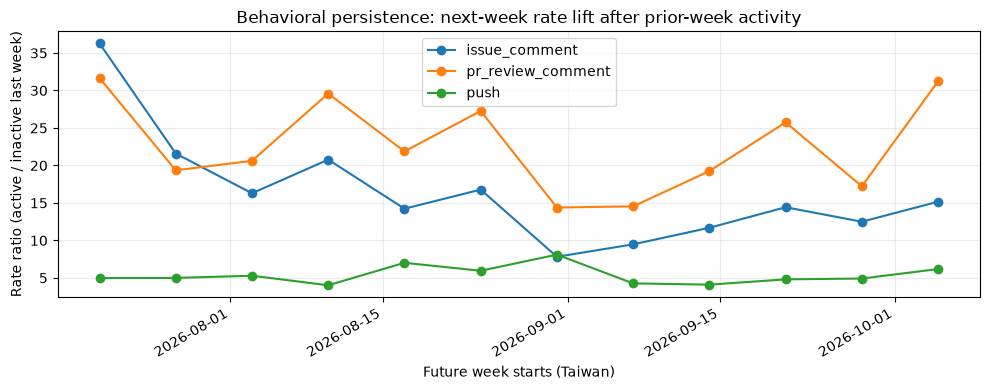

In [9]:
persistence_rows=[]
for signal in DIRECT_SIGNALS:
    d=observations[signal]
    byweek={w:set(s.dropna().astype("int64")) for w,s in d.groupby("week_tw")["internal_user_id"]}
    for week in recent_weeks:
        prior=set(byweek.get(week-pd.Timedelta(days=7), set()))
        current=set(byweek.get(week, set()))
        previous_active=len(prior)
        still_active=len(prior&current)
        inactive_pool=COHORT_SIZE-previous_active
        newly_active=len(current-prior)
        active_rate=still_active/previous_active if previous_active else np.nan
        inactive_rate=newly_active/inactive_pool if inactive_pool else np.nan
        persistence_rows.append({"signal":signal,"week_Taiwan":week.date(),
             "previous_active_users":previous_active,"future_active_users":len(current),
             "p_future_if_prior_active":active_rate,
             "p_future_if_prior_inactive":inactive_rate,
             "lift":active_rate/inactive_rate if pd.notna(active_rate) and inactive_rate>0 else np.nan})
persistence_df=pd.DataFrame(persistence_rows)
display(persistence_df.groupby("signal")[["p_future_if_prior_active","p_future_if_prior_inactive","lift"]]
        .agg(["median","min","max"]).round(3))
fig,ax=plt.subplots(figsize=(10,4))
for signal,g in persistence_df.groupby("signal"):
    ax.plot(pd.to_datetime(g.week_Taiwan),g.lift,label=signal,marker="o")
ax.set_title("Behavioral persistence: next-week rate lift after prior-week activity")
ax.set_xlabel("Future week starts (Taiwan)");ax.set_ylabel("Rate ratio (active / inactive last week)")
ax.legend();ax.grid(alpha=.25);fig.autofmt_xdate();fig.tight_layout();plt.show()

## 9. Is repository engagement breadth associated with next-week pushes?

Use **only the 30 days before each cutoff** to calculate how many distinct repositories each user pushed to, and compare their probability of pushing in the *following* complete week. This demonstrates a possible relational feature and reveals differences between inactive, single-repository, and multi-repository users.

This is a descriptive association, **not an ablation**, not a causal effect, and not a trained model. It may partly reflect differences in prior activity volume; a later controlled model comparison is necessary.

,mean_users_per_week,median_future_push_pct,min_future_push_pct,max_future_push_pct
prior_30d_unique_repos,,,,
0,4565.75,5.26,1.24,10.54
1,2099.58,31.28,7.29,47.50
2–3,1456.08,46.36,14.87,67.56
4+,878.58,70.65,31.36,90.27


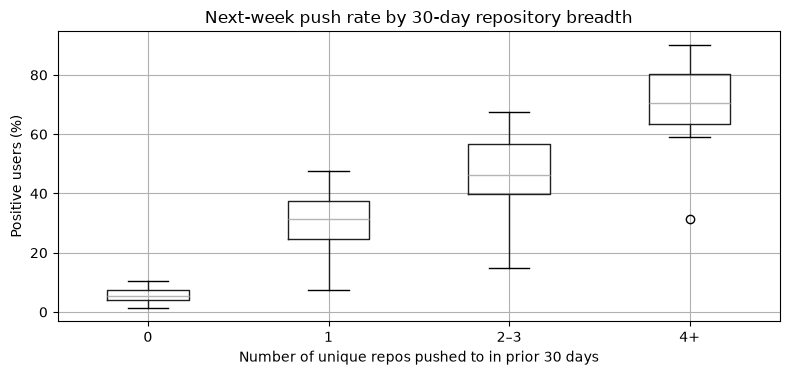

In [10]:
push_df=observations["push"]
rel_rows=[]
for week in recent_weeks:
    start=cutoff_utc(week)
    past=push_df.loc[(push_df.timestamp_utc>=start-pd.Timedelta(days=RELATIONAL_LOOKBACK_DAYS))&
                      (push_df.timestamp_utc<start)]
    repo_counts=past.groupby("internal_user_id").repo_id.nunique().reindex(cohort_ids,fill_value=0)
    lastweek=push_df.loc[(push_df.timestamp_utc>=start)&
                         (push_df.timestamp_utc<start+pd.Timedelta(days=7))]
    positive_ids=set(lastweek.internal_user_id)
    labels=pd.Series(cohort_ids.isin(positive_ids),index=cohort_ids)
    segments=pd.cut(repo_counts,bins=[-1,0,1,3,np.inf],labels=["0","1","2–3","4+"])
    for name in ["0","1","2–3","4+"]:
        selected=labels.loc[segments.eq(name)]
        rel_rows.append({"week_Taiwan":week.date(),"prior_30d_unique_repos":name,
                         "n":len(selected),"next_week_push_users":int(selected.sum()),
                         "next_week_push_pct":round(100*selected.mean(),2) if len(selected) else np.nan})
relationship_df=pd.DataFrame(rel_rows)
display(relationship_df.groupby("prior_30d_unique_repos",sort=False).agg(
    mean_users_per_week=("n","mean"),median_future_push_pct=("next_week_push_pct","median"),
    min_future_push_pct=("next_week_push_pct","min"),max_future_push_pct=("next_week_push_pct","max")).round(2))
ax=relationship_df.boxplot(column="next_week_push_pct",by="prior_30d_unique_repos",figsize=(8,4))
plt.suptitle("");ax.set_title("Next-week push rate by 30-day repository breadth")
ax.set_xlabel("Number of unique repos pushed to in prior 30 days")
ax.set_ylabel("Positive users (%)");plt.tight_layout();plt.show()

## 10. Compare daily snapshots (read-only)

Notebook 01 optionally writes `experiments/eda_snapshot_history.jsonl`. If available, compare the newest logged release to the snapshot currently loaded. **No file is written by this notebook.** A new timestamp from rerunning a clone is not a new upstream release; use the instructor commit SHA when available.

In [11]:
history=[]
if HISTORY_LOG.is_file():
    for line in HISTORY_LOG.read_text(encoding="utf-8").splitlines():
        try:
            if line.strip(): history.append(json.loads(line))
        except json.JSONDecodeError:
            print("Skipped malformed history line")
current_counts={r.table:int(r.rows) for r in release_df.itertuples()}
print("Current official SHA:", sha or "unknown")
if history:
    print("Logged snapshots:",len(history))
    recent=history[-1]
    print("Latest logged SHA:",recent.get("official_repo_sha"))
    display(pd.DataFrame([{"table":table, "last_logged_rows":recent.get("table_rows",{}).get(table),
                           "current_rows":current_counts[table],
                           "difference":current_counts[table]-recent.get("table_rows",{}).get(table,0)}
                          for table in TABLES]))
    if recent.get("official_repo_sha")==sha and sha:
        print("The current clone matches the last logged instructor commit.")
else:
    print("No previous snapshot history log found. Re-run 01 to create it if desired.")

test_path=OFFICIAL_REPO/"evaluation/test_input.csv"
if test_path.exists():
    official_test=pd.read_csv(test_path)
    if list(official_test.columns)!=["UserID"]:
        print("WARNING: unexpected test header:", list(official_test.columns))
    else:
        in_cohort=official_test.UserID.isin(cohort.github_user_id)
        print("Official test_input.csv:",len(official_test), "users; cohort matches:",int(in_cohort.sum()))
else:
    print("Official test_input.csv not present in this snapshot; expected from Oct 28.")

Current official SHA: 506d860693df60a698b68aa63a8edb4a984c8e1b
Logged snapshots: 1
Latest logged SHA: 506d860693df60a698b68aa63a8edb4a984c8e1b


,table,last_logged_rows,current_rows,difference
0,Users,45590,45590,0
1,Repositories,109081,109081,0
2,PullRequests,301518,301518,0
3,Issues,172007,172007,0
4,IssueComments,106204,106204,0
5,PRReviews,90710,90710,0
6,PRReviewComments,66422,66422,0
7,Pushes,1661256,1661256,0


The current clone matches the last logged instructor commit.
Official test_input.csv not present in this snapshot; expected from Oct 28.


## 11. Current-release conclusions and next engineering decisions

The following compact printout is **computed from the current data**, not copied from notebook 01. It is intended to be useful as an agent handoff after each new daily release.

In [12]:
def format_val(x, suffix=""):
    return "n/a" if pd.isna(x) else f"{x:,.2f}{suffix}"

print("="*75)
print("FOLLOW-UP EDA SUMMARY —", (sha[:12] if sha else "unversioned clone"))
print("="*75)
print("Data rows:",f"{int(release_df.rows.sum()):,}","| cohort:",COHORT_SIZE,
      "| last observed (TW):",observed_max_tw)
print("Complete calendar weeks analyzed:",len(complete_weeks),"| recent cutoffs:",len(recent_weeks))
print("\nFirst-seen visibility delays in cohort-attributed rows (paired timestamps):")
for r in lag_df.loc[lag_df.scope.eq("cohort_actor")].itertuples():
    print(f"  {r.table:<17} missing-event={r.event_time_missing_pct:.2f}% "
          f"seen >7d late={r.delay_gt_7d_pct_of_paired:.2f}%")
print("\nBehavioral persistence (median recent-week lift, direct events):")
for signal,g in persistence_df.groupby("signal"):
    print(f"  {signal:<18} {format_val(g.lift.median())}x")
print("\nSelection proxy: median recent-week eligible share:",
      format_val(selection_df.eligible_pct.median(),"%"))
print("\nConclusions still requiring evidence:")
print("  • Weekly drop/recovery may reflect cohort behavior, collection artifacts, or both.")
print("  • 'open_pr', 'open_issue', 'pr_review' remain OBSERVATION proxies, not official labels.")
print("  • Relative activity and repository engagement are candidates for modeling; "
      "prediction gains have NOT been measured.")
print("\nRecommended next milestone: audit target-label semantics and write a "
      "time-safe historical dataset builder; then evaluate a simple baseline.")

FOLLOW-UP EDA SUMMARY — 506d860693df
Data rows: 2,552,788 | cohort: 9000 | last observed (TW): 2026-10-13 20:59:29+08:00
Complete calendar weeks analyzed: 45 | recent cutoffs: 12

First-seen visibility delays in cohort-attributed rows (paired timestamps):
  PullRequests      missing-event=0.00% seen >7d late=1.16%
  Issues            missing-event=0.00% seen >7d late=10.82%
  PRReviews         missing-event=0.00% seen >7d late=0.03%

Behavioral persistence (median recent-week lift, direct events):
  issue_comment      14.79x
  pr_review_comment  21.24x
  push               4.99x

Selection proxy: median recent-week eligible share: 71.23%

Conclusions still requiring evidence:
  • Weekly drop/recovery may reflect cohort behavior, collection artifacts, or both.
  • 'open_pr', 'open_issue', 'pr_review' remain OBSERVATION proxies, not official labels.
  • Relative activity and repository engagement are candidates for modeling; prediction gains have NOT been measured.

Recommended next mile

## 12. Decision log and what this notebook **does not** prove

| Question | Evidence to examine here | What would resolve uncertainty |
|---|---|---|
| Why did activity fall during June–August? | §5 absolute active users, per-active intensity, §5.1 turnover | Inspect stable-cohort event coverage and historical releases; cannot assert collection failure or real seasonality from a single snapshot. |
| Can we infer historical `open_pr`, `open_issue`, `pr_review` labels? | §6 missingness and delays; §6.1 proxy-versus-event-time disagreements | Determine event/action provenance within allowed official data. If impossible, explicitly document label approximation rather than claiming ground truth. |
| Are future test users like all 9,000 users? | §7 approximate activity-based selection | When `test_input.csv` appears Oct 28, examine those actual IDs using only provided data. |
| How predictable is future activity from recent behavior? | §8 conditional rates on **direct** event tables | Build time-respecting train/validation/test examples; calculate the official macro/micro-F1 with held-out weekly labels. |
| Does relational information help? | §9 repository breadth versus next-week pushes | Train/evaluate baseline vs +relational features on identical historical temporal splits. |
| Does the latest course release change results? | §3 snapshot SHA/coverage and §10 comparison to 01 log | Re-clone after 21:00 TW and rerun both notebooks. Preserve a historical snapshot if reproducibility is essential. |

**Hard boundaries for subsequent agents:**

- Use **only the official provided course dataset**; do not scrape or query GitHub/GH Archive APIs.
- For historical features, filter each table by its **row visibility time** (`first_seen_at` for entities/reviews; `created_at` for direct event tables). Exclude or correctly mask `PullRequests.merged_at`, `PullRequests.merged_by_id`, `PullRequests.closed_at`, `Issues.closed_at`, `Issues.state_reason`, `PRReviews.dismissed_at`.
- Do **not** claim observation-proxy counts are actual PR-open/issue-open/review ground truth.
- Use `github_user_id` for external/test identity. Internally, every refresh can renumber PK/FK row indices.
- Use the exact official score `(macro-F1+micro-F1)/2` once valid labels exist. This notebook contains **no trained predictive model, no reported F1, and no final CSV**.
- For any comparison across data releases, document the Git SHA, cutoff, and release; the dataset can be retroactively updated.

**Primary references (local):** `assignment2/data/README.md`, `data/legacy/assignment2/data/db/SCHEMA.md`, `assignment2/evaluation/README.md`, assignment PDF, and `docs/ASSIGNMENT_REFERENCE.md` (if present). This notebook stands alone without them for interpreting its own plots, but they remain the authoritative instructions.